## Negative generic-domain DC-PMI

At each step, use the negative of generic-domain DC-PMI as the error score: lower DC-PMI means a larger error signal. Unlike first differences, this can score every step. The original notebook's first-error AUC excludes post-error steps because their correctness is unknown; show both that verified-only evaluation and the exploratory all-steps evaluation used in the signal comparison. Read only the cached 1000-solution run; do not run inference.

,signal,subset,auc,steps,first_errors,coverage
0,negative_generic_pmi,eligible,0.738305,7012,508,1.0
1,negative_generic_pmi,common,0.738305,7012,508,1.0
2,negative_generic_pmi,all_steps_neutral,0.738305,7012,508,1.0


,signal,subset,auc,steps,first_errors,coverage
0,negative_generic_pmi,eligible,0.695862,4870,508,1.0
1,negative_generic_pmi,common,0.695862,4870,508,1.0
2,negative_generic_pmi,all_steps_neutral,0.695862,4870,508,1.0


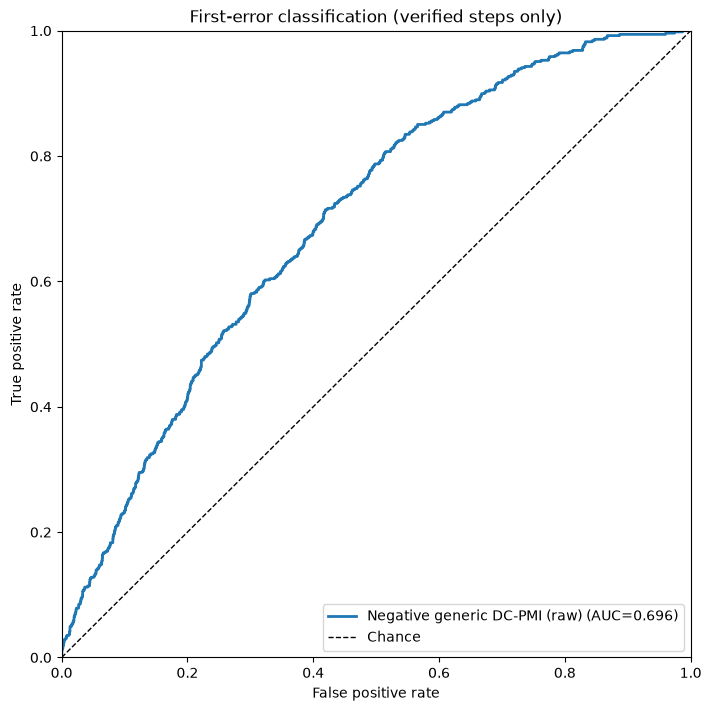

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve().parent
assert ROOT.name == "mr-gsm8k", "Run this notebook from signal_experiments/"
sys.path.insert(0, str(ROOT))
from plots import plot_first_error_roc
from score_dc_pmi import SIGNAL_TITLES, evaluate_signal_scores, load_signal_cache

steps = load_signal_cache(
    ROOT / "cache/llama_3_mr_gsm8k_original_n1000_seed42_token_logprobs.parquet",
    ROOT / "signal_experiments/cache/signals_n1000_seed42.parquet",
)
assert steps.uuid.nunique() == 1000
column = "negative_generic_pmi"
display(evaluate_signal_scores(steps, [column]))
verified = steps.loc[steps.verified_step]
display(evaluate_signal_scores(steps, [column], verified_only=True))

fig, ax, roc_rows = plot_first_error_roc(
    verified.first_error,
    {SIGNAL_TITLES[column]: verified[column]},
    title="First-error classification (verified steps only)",
)
plt.show()

## Signal distribution at individual steps

Compare first-error steps with verified correct controls sampled at the same absolute step number. Set `SHOW_ALL_VERIFIED_CORRECT` to also show the full verified-correct cohort; the matched controls are included in that cohort. Histograms use density scaling and shared bins.

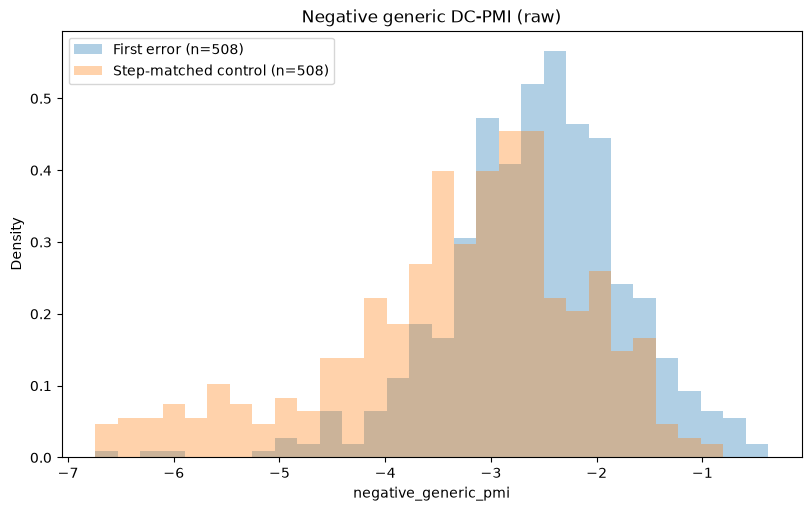

In [ ]:
from plots import plot_first_error_histogram

SHOW_ALL_VERIFIED_CORRECT = False
fig, ax, groups = plot_first_error_histogram(
    steps,
    column,
    title=SIGNAL_TITLES[column],
    seed=42,
    show_all_verified_correct=SHOW_ALL_VERIFIED_CORRECT,
)
assert groups["First error"].groupby("step").size().equals(
    groups["Step-matched control"].groupby("step").size()
)
plt.show()